<a href="https://colab.research.google.com/github/a00377571/lsm-reconocimiento-mediapipe/blob/main/An%C3%A1lisis_exploratorio_EDA_E47.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Maestría en Inteligencia Artificial Aplicada**.

**Curso: TC5035.10 - Proyecto Integrador**

Tecnológico de Monterrey

Profesor: Dr. Raúl Valente Ramírez Velarde

**Semana 2, Actividad 1**

Análisis Exploratorio de datos

---

*   **Estudiante:** Marco Antonio Arellano Hernández - A00377571
*   **Estudiante:** Miguel Octavio Ramírez Romero - A00828311
*   **Estudiante:** Hugo Enrique Navarro Villeda - A01796287

# **Parte 1: EDA y preprocesamiento**

**Importar módulos requeridos**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import os

In [31]:
# Cargar archivo CSV

df = pd.read_csv("dataset_base.csv")

print("Lectura de archivo CSV que contiene el dataset:")
print(df.head())

Lectura de archivo CSV que contiene el dataset:
   video_id  frame_id  timestamp   label  left_detectada  right_x0  right_y0  \
0         0         0          0  Word-A               0  0.286312  0.566639   
1         1         0          0  Word-A               0  0.269283  0.517021   
2         2         0          0  Word-A               1       NaN       NaN   
3         3         0          0  Word_-               0  0.238336  0.622394   
4         4         0          0  Word_A               0  0.374317  0.441127   

       right_z0  right_x1  right_y1  ...  left_angle_pinky_mcp  \
0 -2.310000e-07  0.324800  0.547244  ...                   NaN   
1 -2.150000e-07  0.296912  0.500848  ...                   NaN   
2           NaN       NaN       NaN  ...            161.650404   
3 -2.310000e-07  0.312799  0.584109  ...                   NaN   
4 -1.250000e-07  0.393573  0.431170  ...                   NaN   

   left_angle_between_index_middle  left_angle_between_middle_ring  \
0   

In [32]:
# Informacion básico del dataset
print("-"*50)
print("Informacion basica sobre el dataset:")
print("-"*50)
df.info()

print("-"*50)
print("Tipos de las columnas del dataset")
print("-"*50)
df.dtypes

--------------------------------------------------
Informacion basica sobre el dataset:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 539 entries, 0 to 538
Columns: 227 entries, video_id to left_wrist_z
dtypes: float64(218), int64(8), object(1)
memory usage: 956.0+ KB
--------------------------------------------------
Tipos de las columnas del dataset
--------------------------------------------------


,0
video_id,int64
frame_id,int64
timestamp,int64
label,object
left_detectada,int64
...,...
left_hand_ori_x,float64
left_hand_ori_y,float64
left_wrist_x,float64
left_wrist_y,float64


In [33]:
numerical_columns = df.select_dtypes(include = ['int', 'float']).columns
categorical_columns = df.select_dtypes(include = ['object','category']).columns

print("Columnas por categoria")
print("Columnas numericas: ", numerical_columns.to_list())
print("Columnas categoricas: ", categorical_columns.to_list())
print(f"Numero de columnas numericas: {len(numerical_columns)}")
print(f"Numbero de columnas categoricas: {len(categorical_columns)}")

Columnas por categoria
Columnas numericas:  ['video_id', 'frame_id', 'timestamp', 'left_detectada', 'right_x0', 'right_y0', 'right_z0', 'right_x1', 'right_y1', 'right_z1', 'right_x2', 'right_y2', 'right_z2', 'right_x3', 'right_y3', 'right_z3', 'right_x4', 'right_y4', 'right_z4', 'right_x5', 'right_y5', 'right_z5', 'right_x6', 'right_y6', 'right_z6', 'right_x7', 'right_y7', 'right_z7', 'right_x8', 'right_y8', 'right_z8', 'right_x9', 'right_y9', 'right_z9', 'right_x10', 'right_y10', 'right_z10', 'right_x11', 'right_y11', 'right_z11', 'right_x12', 'right_y12', 'right_z12', 'right_x13', 'right_y13', 'right_z13', 'right_x14', 'right_y14', 'right_z14', 'right_x15', 'right_y15', 'right_z15', 'right_x16', 'right_y16', 'right_z16', 'right_x17', 'right_y17', 'right_z17', 'right_x18', 'right_y18', 'right_z18', 'right_x19', 'right_y19', 'right_z19', 'right_x20', 'right_y20', 'right_z20', 'right_dist_1', 'right_dist_2', 'right_dist_3', 'right_dist_4', 'right_dist_5', 'right_dist_6', 'right_dist_7',

In [34]:
# Muestreo de estadisticas generales de las columnas numericas
df[numerical_columns].describe()

,video_id,frame_id,timestamp,left_detectada,right_x0,right_y0,right_z0,right_x1,right_y1,right_z1,...,left_angle_pinky_mcp,left_angle_between_index_middle,left_angle_between_middle_ring,left_angle_between_ring_pinky,left_angle_between_index_pinky,left_hand_ori_x,left_hand_ori_y,left_wrist_x,left_wrist_y,left_wrist_z
count,539.000000,539.0,539.0,539.000000,304.000000,304.000000,3.040000e+02,304.000000,304.000000,304.000000,...,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,2.400000e+02
mean,269.000000,0.0,0.0,0.445269,0.267727,0.615666,1.592488e-07,0.310753,0.589819,-0.013712,...,127.107760,13.937812,14.439000,15.861176,43.514092,-0.043032,-0.125194,0.731429,0.691916,-2.768616e-07
std,155.740168,0.0,0.0,0.497457,0.096520,0.162838,3.492998e-07,0.089773,0.148416,0.017285,...,34.403552,6.607304,5.384300,6.517487,15.258479,0.084552,0.109649,0.180660,0.164337,4.707442e-07
min,0.000000,0.0,0.0,0.000000,0.057537,0.185685,-7.320000e-07,0.089266,0.203686,-0.097146,...,33.697693,4.389582,3.953052,3.757996,11.261378,-0.425323,-0.369252,0.038829,0.219118,-1.970000e-06
25%,134.500000,0.0,0.0,0.000000,0.196828,0.498072,-4.015000e-08,0.244081,0.480026,-0.020339,...,102.994874,9.892710,10.451861,11.301413,32.645342,-0.082716,-0.205750,0.674810,0.586973,-6.282500e-07
50%,269.000000,0.0,0.0,0.000000,0.267299,0.606028,1.072643e-07,0.312436,0.575302,-0.011355,...,134.352031,13.434104,14.014408,16.303105,42.914251,-0.033278,-0.148656,0.768497,0.714751,-2.420000e-07
75%,403.500000,0.0,0.0,1.000000,0.334270,0.723876,3.270127e-07,0.374596,0.690214,-0.004956,...,155.535474,16.433451,17.830795,20.102930,52.963625,0.002780,-0.061052,0.840823,0.817525,9.915176e-08
max,538.000000,0.0,0.0,1.000000,0.602477,1.051780,2.004499e-06,0.672690,0.998765,0.069328,...,173.359093,74.925073,32.056649,42.859958,109.204757,0.287883,0.179421,1.058479,0.996318,1.291141e-06


In [35]:
# Muestreo de estadisticas generales de la columna categorica
df[categorical_columns].describe()

,label
count,539
unique,28
top,Word_N
freq,34


In [36]:
df[categorical_columns].apply(lambda x: x.unique()).T

,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
label,Word-A,Word_-,Word_A,Word_B,Word_C,Word_D,Word_E,Word_F,Word_G,Word_H,...,Word_Q,Word_R,Word_S,Word_T,Word_U,Word_V,Word_W,Word_X,Word_Z,Word_y


# **Descripción general del dataset**

Este dataset contiene datos de landmarks (puntos clave) de manos detectadas en video, con el objetivo de clasificar señas o palabras de un lenguaje de señas LSM. Para fines de esta práctica, se utilizaron imágenes fijas.


*   **Dimensiones:** 539 filas x 228 columnas
*   **Tamaño:** dataset mediano
*   **Formato:** cada fila representa un frame de un video con la informacion de las manos detectadas

**Variable objetivo: label**

Contiene la etiqueta de la seña/palabra que se está realizando. Los valores observados son:
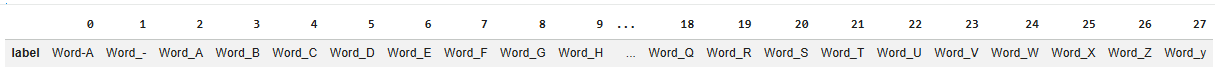


**Estructura de las columnas**

Columnas de identificación y metadatos

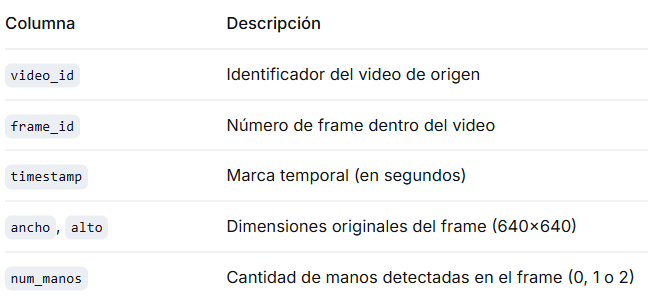

**Columnas de detección**

Existen dos columnas en este apartado: left_detectada y right_detectada, si aparece 1 es que se detectó la mano, 0 si no.

Landmarks por mano (21 puntos x 3 coordenadas por mano)

Para cada mano (left y right) hay:
{mano}_x0..x20, {mano}_y0..y20, {mano}_z0..z20: coordenadas normalizadas (0-1) de los 21 puntos clave de MediaPipe.

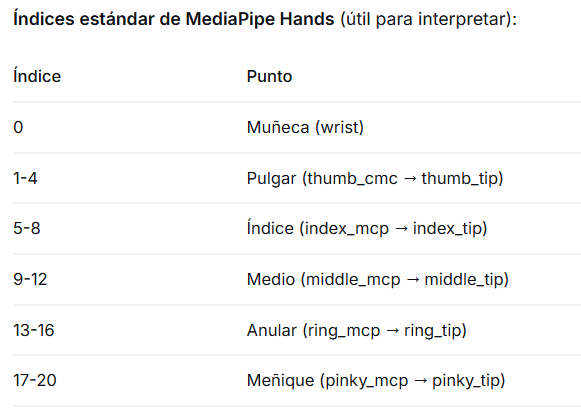


**Features multi-mano**


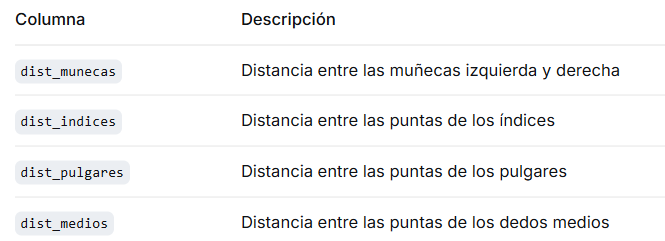

Estos capturan interacción entre las dos manos, podría ser clave para señas bimanuales.


**Particularidades importantes**

* **Muchos valores nulos (NaN):** Cuando no se detecta una mano, todas sus columnas quedan vacías
* **Datos repetidos por frame:** Un mismo video aporta muchas filas lo que genera un desbalance temporal; por otro lado, una fuga de datos si se divide aleotariamente y no se toma en cuenta dividir por video_id y no por fila.
* **Coordenadas normalizadas:** Las coordenadas x,y están en [0,1] respecto al frame



# **Valores faltantes o nulos**

In [22]:
!pip install missingno

In [37]:
# Conteo global de nulos
nulos = df.isnull().sum()
pct_nulos = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({"nulos": nulos, "pct": pct_nulos}).sort_values("pct", ascending=False)
print(resumen_nulos[resumen_nulos["nulos"] > 0].head(20))
print(f"\nTotal columnas con nulos: {(nulos > 0).sum()} de {df.shape[1]}")

                       nulos    pct
dist_medios              515  95.55
dist_munecas             515  95.55
dist_indices             515  95.55
dist_pulgares            515  95.55
left_dist_11             299  55.47
left_dist_10             299  55.47
left_dist_9              299  55.47
left_dist_12             299  55.47
left_dist_7              299  55.47
left_dist_6              299  55.47
left_dist_5              299  55.47
left_dist_4              299  55.47
left_dist_3              299  55.47
left_dist_2              299  55.47
left_dist_1              299  55.47
left_dist_8              299  55.47
left_y20                 299  55.47
left_x20                 299  55.47
left_angle_middle_mcp    299  55.47
left_angle_middle_dip    299  55.47

Total columnas con nulos: 218 de 227


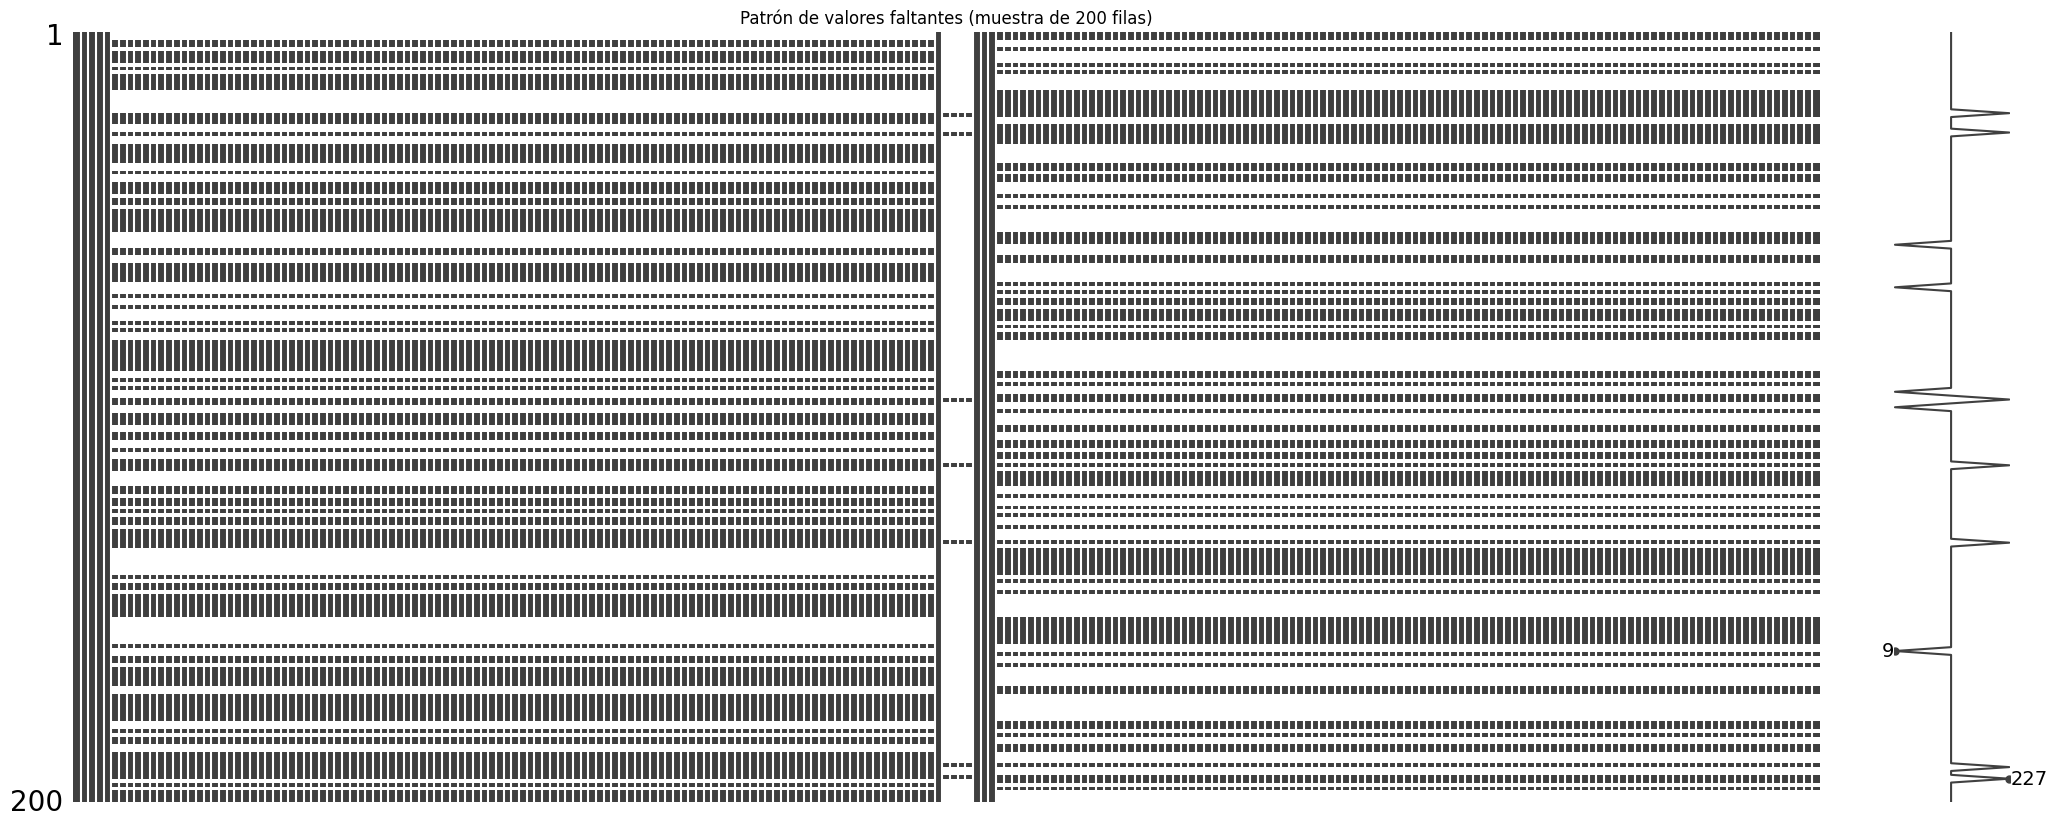

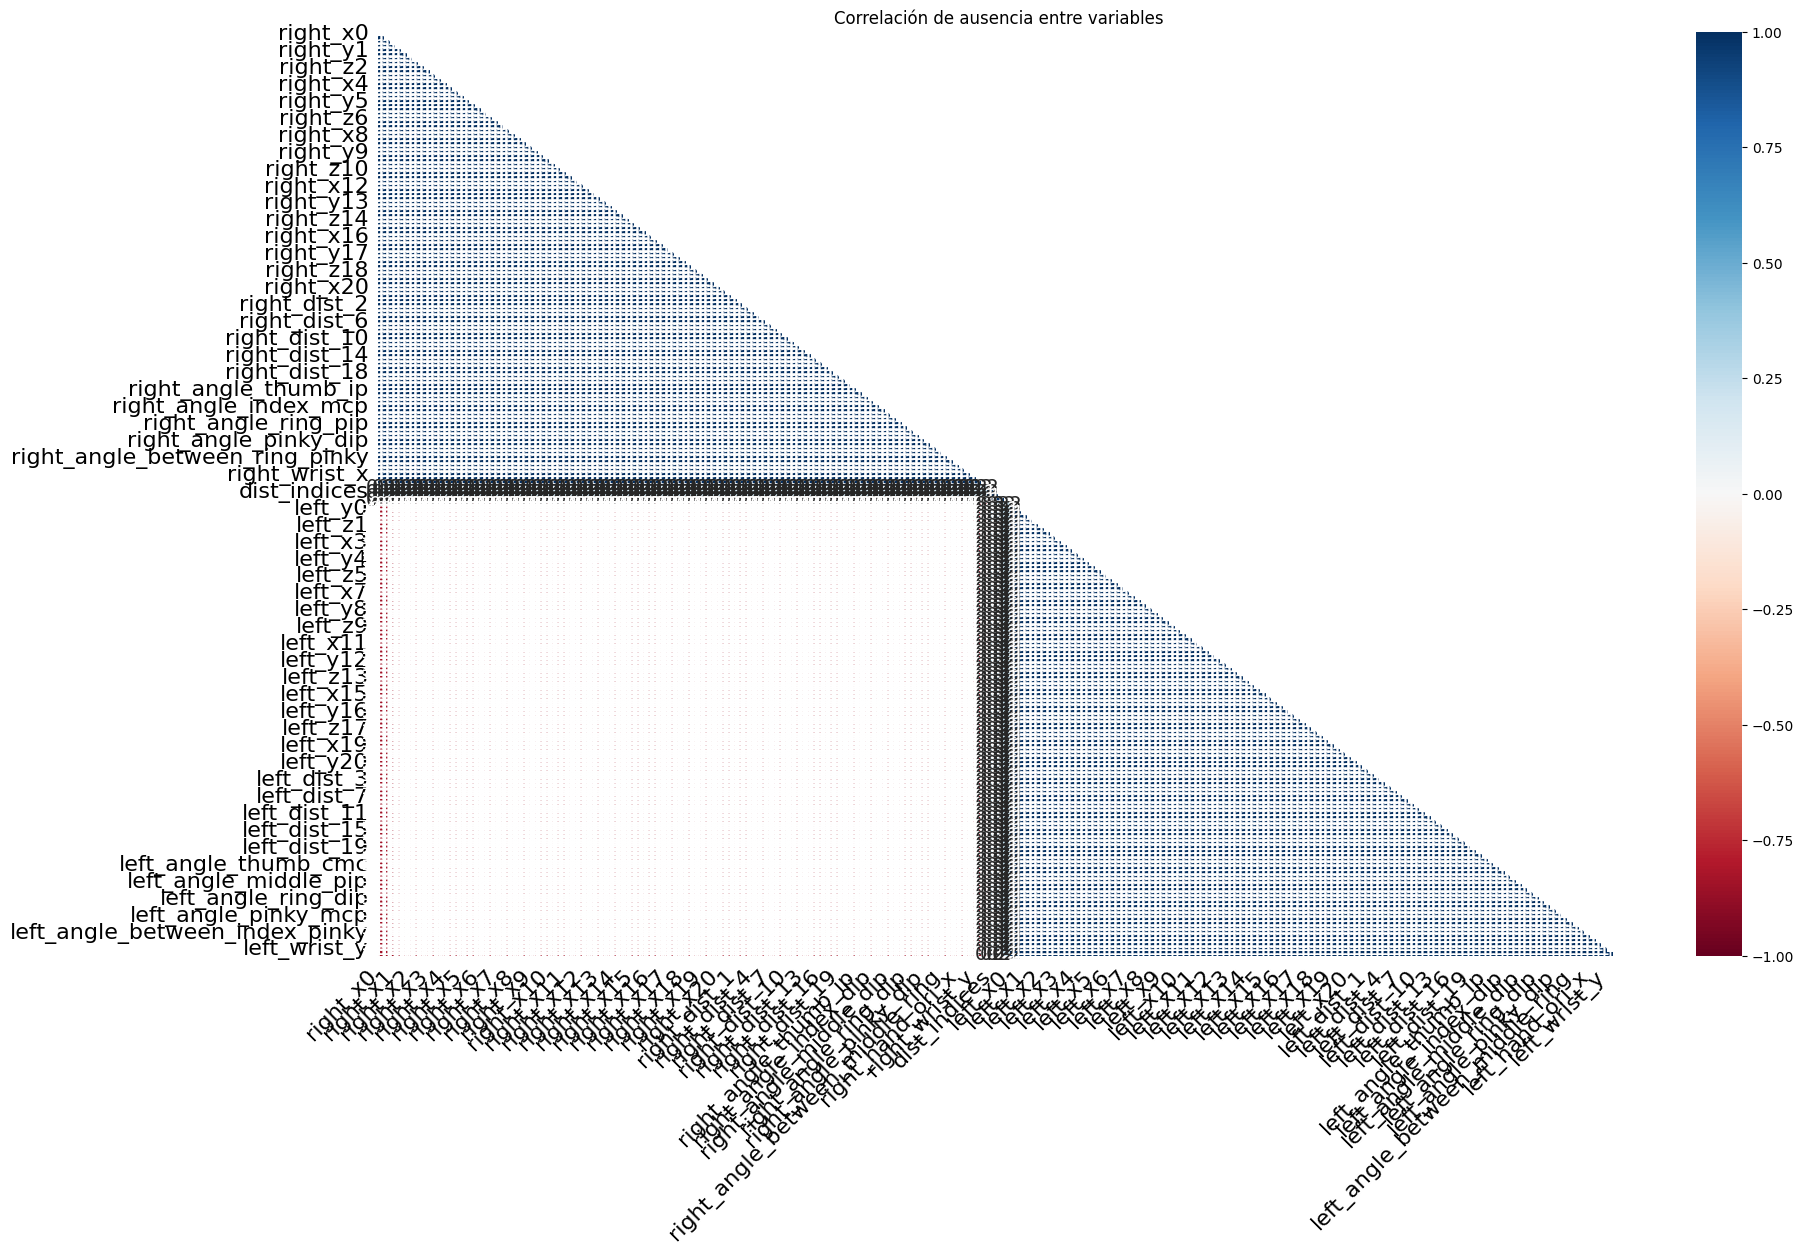

In [38]:
# Viendolo de manera visual con patron y correlacion
import missingno as msno

msno.matrix(df.sample(200, random_state=42))
plt.title("Patrón de valores faltantes (muestra de 200 filas)")
plt.show()

msno.heatmap(df)
plt.title("Correlación de ausencia entre variables")
plt.show()

In [39]:
# Verificar: cuando left_detectada == 0, ¿están nulas las columnas left_*?
left_cols = [c for c in df.columns if c.startswith("left_") and c != "left_detectada"]
mask = df["left_detectada"] == 0
print(f"Filas sin mano izquierda: {mask.sum()}")
print(f"De esas, ¿cuántas tienen todos los landmarks left nulos? "
      f"{df.loc[mask, left_cols].isnull().all(axis=1).sum()}")

# Igual para la derecha
right_cols = [c for c in df.columns if c.startswith("right_") and c != "right_detectada"]
mask = df["right_detectada"] == 0
print(f"Filas sin mano derecha: {mask.sum()}")
print(f"De esas, ¿todas right nulas? "
      f"{df.loc[mask, right_cols].isnull().all(axis=1).sum()}")

Filas sin mano izquierda: 299
De esas, ¿cuántas tienen todos los landmarks left nulos? 299
Filas sin mano derecha: 235
De esas, ¿todas right nulas? 235


Conclusión: los nulos son estructurales, no aleatorios por lo que se deben tratar como "mano ausente", no imputar con media/mediana.

manos_detectadas
1    0.920
2    0.045
0    0.035
Name: proportion, dtype: float64


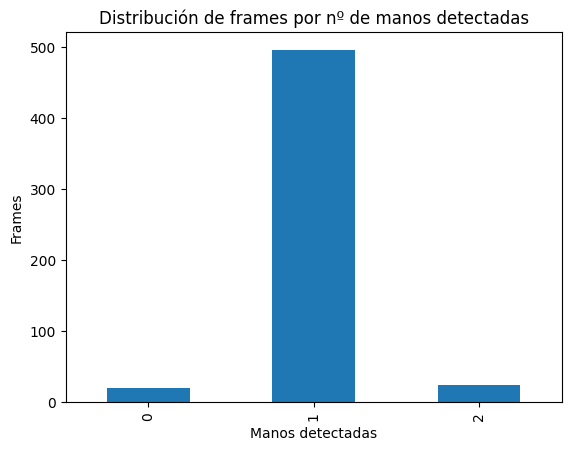

In [40]:
df["manos_detectadas"] = df["left_detectada"] + df["right_detectada"]
print(df["manos_detectadas"].value_counts(normalize=True).round(3))

df["manos_detectadas"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribución de frames por nº de manos detectadas")
plt.xlabel("Manos detectadas"); plt.ylabel("Frames")
plt.show()

Al ver la distribucion de manos detectadas, haremos una limpieza del dataset para quedarnos con la informacion donde se detecta una mano y excluiremos la otra mano.

In [49]:
df_una = df[(df["left_detectada"] + df["right_detectada"]) == 1].copy()
print(f"Filas originales: {len(df)}")
print(f"Filas con una sola mano: {len(df_una)}")

Filas originales: 539
Filas con una sola mano: 496


In [50]:
# Identificar los "sufijos" comunes de las features de mano
#    Quitamos el prefijo 'left_' y 'right_' para obtener el nombre base
right_cols = [c for c in df.columns if c.startswith("right_") and c != "right_detectada"]
left_cols  = [c for c in df.columns if c.startswith("left_")  and c != "left_detectada"]

# Deben tener el mismo número de columnas para poder mapear 1:1
assert len(right_cols) == len(left_cols), "Los bloques left/right no coinciden"

# Pares (nombre_base, col_right, col_left)
pares = []
for rc, lc in zip(right_cols, left_cols):
    # rc = 'right_x0' -> base 'x0'
    base_right = rc.replace("right_", "", 1)
    base_left  = lc.replace("left_",  "", 1)
    # Sanity check: los sufijos deben coincidir
    assert base_right == base_left, f"No coinciden: {rc} vs {lc}"
    pares.append((base_right, rc, lc))

print(f"Features a unificar: {len(pares)}")

Features a unificar: 107


In [53]:
# Construir el DataFrame unificado
df_hand = df_una[["video_id", "frame_id", "timestamp", "label"]].copy()

# Añadir columnas de identificación
df_hand["mano"] = np.where(df_una["right_detectada"] == 1, "right", "left")

# Copiar features renombradas
for base, rc, lc in pares:
    # where: si es right, toma right_*, si no left_*
    df_hand[base] = np.where(
        df_una["right_detectada"] == 1,
        df_una[rc].values,
        df_una[lc].values,
    )

#Eliminamos las columnas frame_id y timestamp
df_hand = df_hand.drop(columns=["frame_id", "timestamp"])

print("Shape del dataset unificado:", df_hand.shape)
df_hand.head(3)

Shape del dataset unificado: (496, 110)


/tmp/ipykernel_2811/3442214625.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_hand[base] = np.where(
/tmp/ipykernel_2811/3442214625.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_hand[base] = np.where(
/tmp/ipykernel_2811/3442214625.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`

,video_id,label,mano,x0,y0,z0,x1,y1,z1,x2,...,angle_pinky_mcp,angle_between_index_middle,angle_between_middle_ring,angle_between_ring_pinky,angle_between_index_pinky,hand_ori_x,hand_ori_y,wrist_x,wrist_y,wrist_z
0,0,Word-A,right,0.286312,0.566639,-2.310000e-07,0.324800,0.547244,-0.006375,0.352135,...,166.012890,11.262521,12.279316,13.868043,37.244545,0.021848,-0.114968,0.286312,0.566639,-2.310000e-07
1,1,Word-A,right,0.269283,0.517021,-2.150000e-07,0.296912,0.500848,-0.005641,0.318063,...,154.660640,12.410695,11.265674,11.591878,35.019657,0.015415,-0.085924,0.269283,0.517021,-2.150000e-07
2,2,Word-A,left,0.814622,0.580033,-1.400000e-07,0.763331,0.569316,-0.025842,0.725851,...,161.650404,12.974944,13.688894,13.443426,39.768906,-0.036199,-0.125422,0.814622,0.580033,-1.400000e-07


In [54]:
# Verificación de cantidad detectada por manos
print("Distribución de la mano detectada:")
print(df_hand["mano"].value_counts())

# Comprobar que no hay NaN en las features de mano
features_hand = [b for b, _, _ in pares]
print(f"\nTotal NaN en features de mano: {df_hand[features_hand].isnull().sum().sum()}")

Distribución de la mano detectada:
mano
right    280
left     216
Name: count, dtype: int64

Total NaN en features de mano: 0


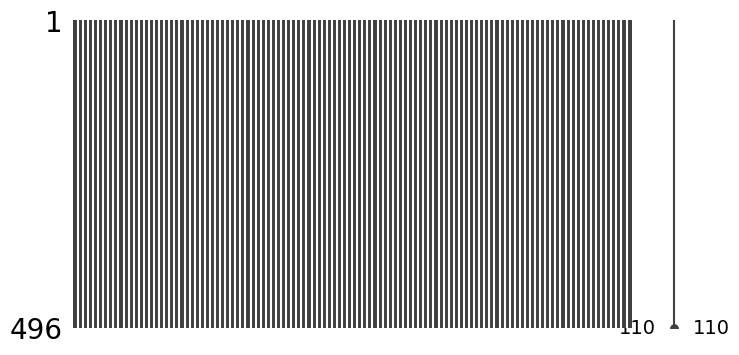

In [55]:
msno.matrix(df_hand, figsize=(8,4))
plt.show()

In [58]:
# Actualizamos las columnas numericas y categoricas
numerical_columns = df_hand.select_dtypes(include = ['int', 'float']).columns
categorical_columns = df_hand.select_dtypes(include = ['object','category']).columns

print("Columnas por categoria")
print("Columnas numericas: ", numerical_columns.to_list())
print("Columnas categoricas: ", categorical_columns.to_list())
print(f"Numero de columnas numericas: {len(numerical_columns)}")
print(f"Numbero de columnas categoricas: {len(categorical_columns)}")

Columnas por categoria
Columnas numericas:  ['video_id', 'x0', 'y0', 'z0', 'x1', 'y1', 'z1', 'x2', 'y2', 'z2', 'x3', 'y3', 'z3', 'x4', 'y4', 'z4', 'x5', 'y5', 'z5', 'x6', 'y6', 'z6', 'x7', 'y7', 'z7', 'x8', 'y8', 'z8', 'x9', 'y9', 'z9', 'x10', 'y10', 'z10', 'x11', 'y11', 'z11', 'x12', 'y12', 'z12', 'x13', 'y13', 'z13', 'x14', 'y14', 'z14', 'x15', 'y15', 'z15', 'x16', 'y16', 'z16', 'x17', 'y17', 'z17', 'x18', 'y18', 'z18', 'x19', 'y19', 'z19', 'x20', 'y20', 'z20', 'dist_1', 'dist_2', 'dist_3', 'dist_4', 'dist_5', 'dist_6', 'dist_7', 'dist_8', 'dist_9', 'dist_10', 'dist_11', 'dist_12', 'dist_13', 'dist_14', 'dist_15', 'dist_16', 'dist_17', 'dist_18', 'dist_19', 'dist_20', 'angle_thumb_mcp', 'angle_thumb_ip', 'angle_thumb_cmc', 'angle_index_pip', 'angle_index_dip', 'angle_index_mcp', 'angle_middle_pip', 'angle_middle_dip', 'angle_middle_mcp', 'angle_ring_pip', 'angle_ring_dip', 'angle_ring_mcp', 'angle_pinky_pip', 'angle_pinky_dip', 'angle_pinky_mcp', 'angle_between_index_middle', 'angle_

# **Analisis de outliers**

In [62]:
## Solo sobre columnas numéricas, excluyendo IDs
cols_features = [c for c in df_hand.columns if c not in ["video_id", "label", "mano"]]
df_hand[cols_features].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
x0,496.0,0.468,0.271,0.039,0.239,0.374,0.750,1.058
y0,496.0,0.650,0.165,0.186,0.528,0.652,0.766,1.052
z0,496.0,-0.000,0.000,-0.000,-0.000,-0.000,0.000,0.000
x1,496.0,0.467,0.218,0.063,0.289,0.399,0.685,0.964
y1,496.0,0.621,0.151,0.204,0.510,0.625,0.723,0.999
...,...,...,...,...,...,...,...,...
hand_ori_x,496.0,-0.002,0.082,-0.425,-0.038,0.008,0.038,0.297
hand_ori_y,496.0,-0.130,0.092,-0.369,-0.192,-0.129,-0.078,0.187
wrist_x,496.0,0.468,0.271,0.039,0.239,0.374,0.750,1.058
wrist_y,496.0,0.650,0.165,0.186,0.528,0.652,0.766,1.052


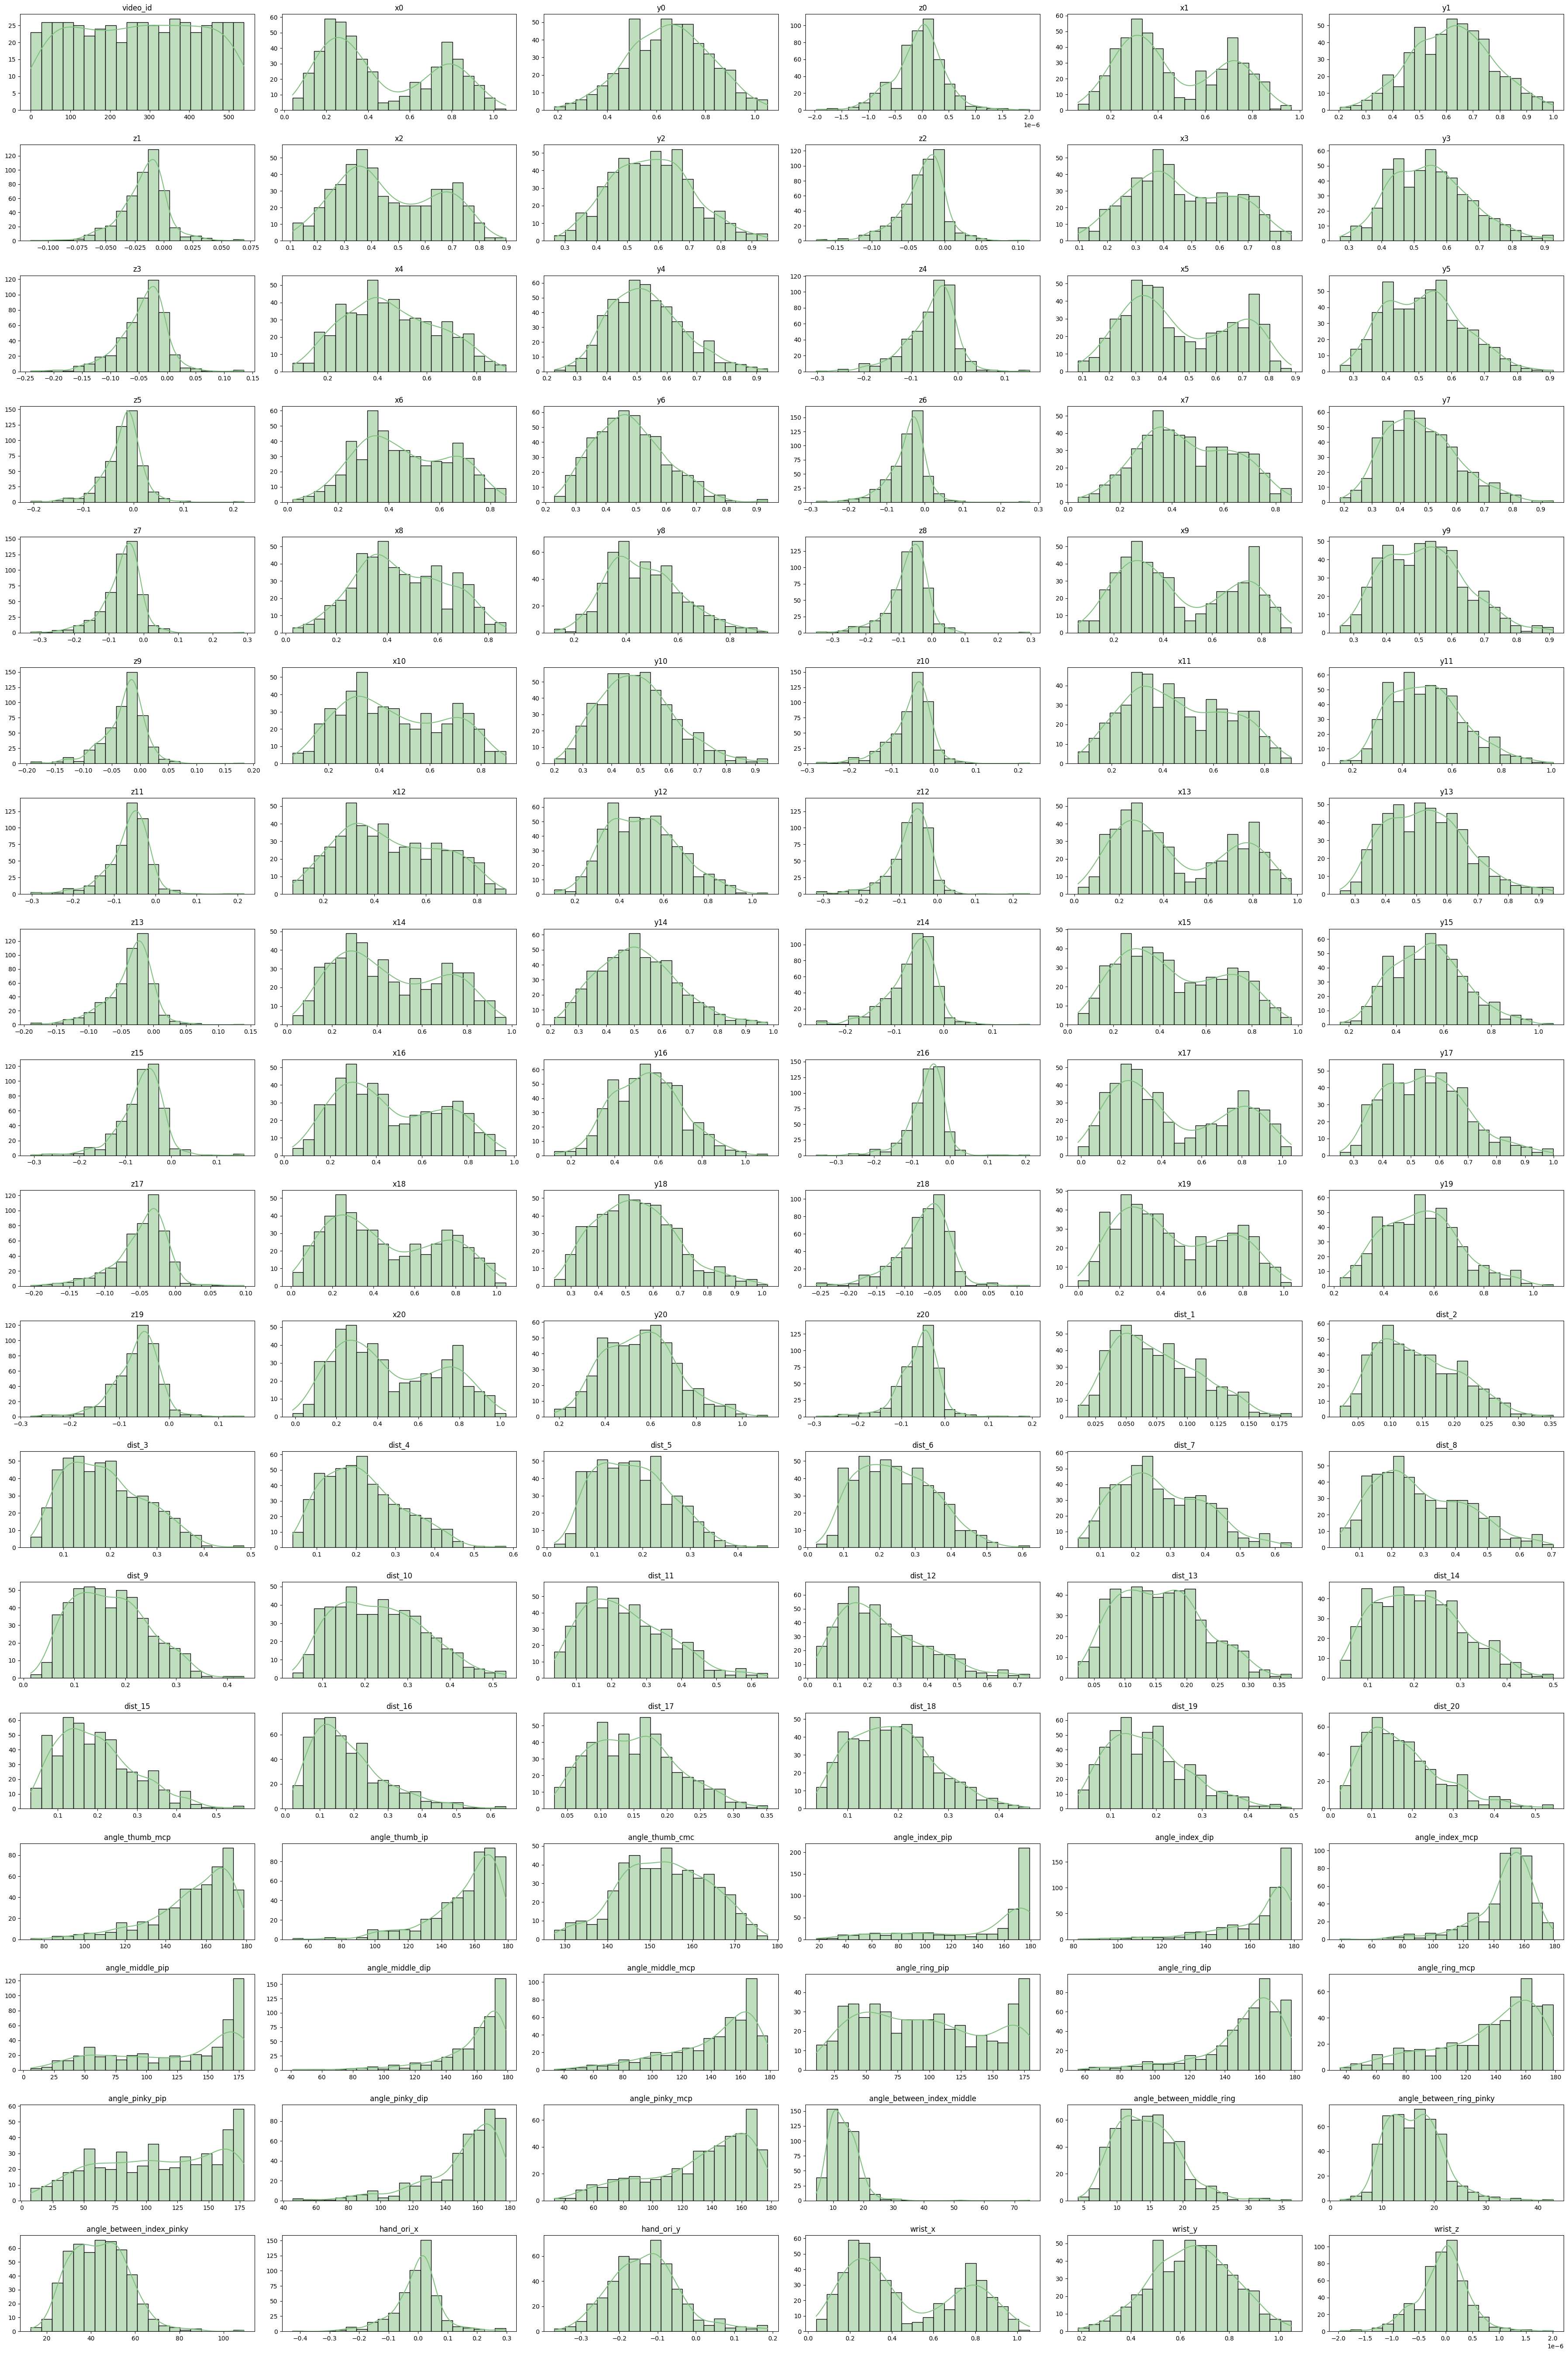

In [60]:
# Establecer tamaño para graficos
n = len(numerical_columns)
ncols = 6
nrows = math.ceil(n / ncols)

# Crear subplots
fig, axes = plt.subplots(nrows, ncols, figsize=(6*ncols, 3*nrows))
axes = axes.flatten()

# Realizar cada subplot
for ax, col in zip(axes, numerical_columns):
    sns.histplot(df_hand[col].dropna(), kde=True, bins=20, ax=ax, color='#7fbf7f')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('')

for ax in axes[n:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

Para es

In [63]:
# Identificacion por IQR
def outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((serie < q1 - 1.5*iqr) | (serie > q3 + 1.5*iqr)).sum()

top_outliers = df_hand[cols_features].apply(outliers_iqr).sort_values(ascending=False)
print("Top 10 columnas con más outliers (IQR):")
print(top_outliers.head(10))

Top 10 columnas con más outliers (IQR):
angle_ring_dip      37
hand_ori_x          37
angle_index_mcp     34
angle_middle_dip    31
z11                 29
angle_pinky_dip     29
z17                 29
z18                 27
angle_index_dip     26
z5                  25
dtype: int64


In [64]:
# Deteccion multivariada con z-score
from scipy.stats import zscore
z = np.abs(zscore(df_hand[cols_features].fillna(0), nan_policy="omit"))
print(f"Filas con al menos un |z| > 4: {(z > 4).any(axis=1).sum()}")

Filas con al menos un |z| > 4: 23


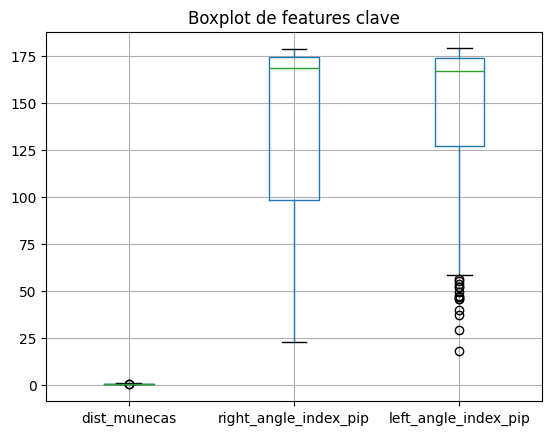

In [43]:
# Boxplots de features clave
features_clave = ["dist_munecas", "right_angle_index_pip", "left_angle_index_pip"]
df[features_clave].boxplot()
plt.title("Boxplot de features clave")
plt.show()

Conclusion: Muchos "outliers" detectados corresponden a posturas reales distintas (no errores), por lo que no deben eliminarse. Como sugerencia se debe usar modelos mas robustos (Random forest o XGBoost) o escalado robusto.

In [46]:
cat_cols = df.select_dtypes(include=["object"]).columns.tolist()
print(f"Columnas categóricas/objeto: {cat_cols}")

for c in cat_cols:
    print(f"\n{c}: {df[c].nunique()} valores únicos")
    print(df[c].value_counts().head(10))

Columnas categóricas/objeto: ['label']

label: 28 valores únicos
label
Word_N    34
Word_R    33
Word_P    26
Word_L    25
Word_Z    24
Word_Q    23
Word_U    22
Word_S    22
Word_W    21
Word_O    21
Name: count, dtype: int64


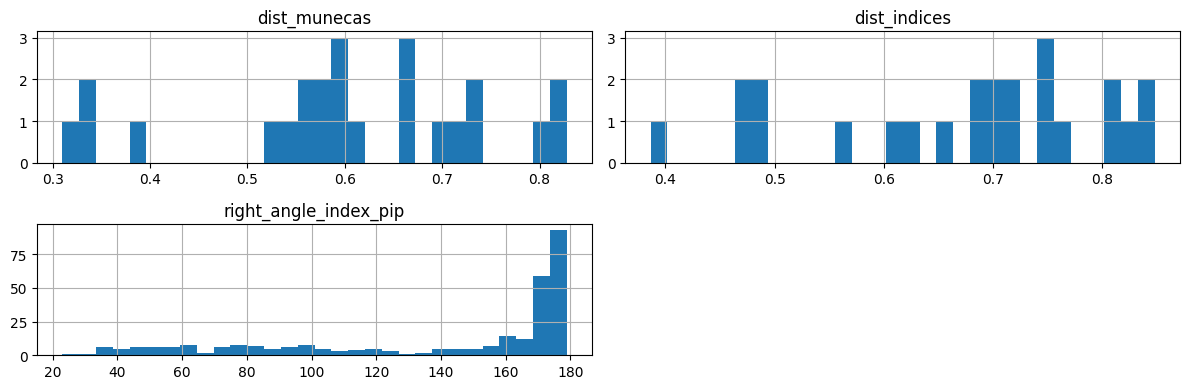

In [47]:
# Histogramas de features clave
df[["dist_munecas", "dist_indices", "right_angle_index_pip"]].hist(bins=30, figsize=(12, 4))
plt.tight_layout(); plt.show()

In [48]:
skew = df[cols_features].skew().sort_values(key=abs, ascending=False)
print("Top 10 features más sesgadas:")
print(skew.head(10).round(2))

# Ver cuántas superan |skew| > 1 (candidatas a transformación)
print(f"\nFeatures con |skew| > 1: {(skew.abs() > 1).sum()}")

Top 10 features más sesgadas:
left_angle_between_index_middle    4.28
right_angle_middle_dip            -2.64
right_angle_ring_dip              -2.15
right_angle_pinky_dip             -2.03
right_angle_index_dip             -1.96
right_angle_index_mcp             -1.86
right_z7                          -1.76
right_z8                          -1.73
right_z6                          -1.72
right_angle_thumb_ip              -1.70
dtype: float64

Features con |skew| > 1: 70
